# C2 – Model training: Grid-Aware Temporal Multi-Criteria Optimization of Charging Station Locations

**Project J26-IT-430 · Component 2 (Where should new chargers be built?)** · kernel: **Python (J26 geo)**

Uses the cleaned layers in `station_siting/data/processed/` (made by `python -m station_siting.data_prep.run_all`).

| Step | Model | Compared with (baseline) |
| --- | --- | --- |
| 2.0 | H3 hexagon grid (res 8 ≈ 0.74 km²) over Colombo District | – |
| 2.1 | **Temporal demand index** per hexagon × 4 periods (+ growth scenarios) | static demand (population only, no periods) |
| 2.2 | **Hotspots**: K-Means + DBSCAN, best by Silhouette / Davies-Bouldin | – |
| 2.3 | **AHP criteria weights** (consistency ratio < 0.1) | equal weights |
| 2.4 | **Site scoring** of real buildable candidates (weighted sum) | static MCDM |
| 2.5 | **MCLP with substation capacity constraint** (MILP, HiGHS) | traffic-only top-N · K-Means centres · MCLP without grid constraint |
| Val. | coverage per period · grid violations · hold-out hit rate · ±20 % weight sensitivity · growth scenarios | – |

**Assumptions (clearly marked ⚠️, replace when real data arrives):** AHP pairwise judgements (expert interviews
pending), POI weights per period, share of substation spare capacity available for EV charging, station size.
Substation capacity = CEB LTTDP 2013–2022 forecast for 2025 (not measured). Distances in EPSG:5235 (metres).

## 0. Setup

In [1]:
import json, sys, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import h3
import rasterio
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.spatial import cKDTree
from scipy.stats import kendalltau
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from shared import config

SEED = config.SEED; rng = np.random.default_rng(SEED)
C2 = ROOT / "station_siting"; PROC = C2 / "data" / "processed"
RES = C2 / "results"; FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
M = 5235  # metric CRS (SLD99)
RESULTS = {"run_id": RUN_ID, "seed": SEED, "config": {}, "metrics": {}}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})
print("root:", ROOT, "| run:", RUN_ID)

root: C:\Users\dasit\Documents\Projects\CSP 002\A Shared Intelligent Infrastructure Framework for Electric Vehicles in Sri Lanka | run: 20261019T092728Z


In [2]:
district = gpd.read_parquet(PROC / "district.parquet")
roads = gpd.read_parquet(PROC / "osm_roads.parquet")
pois = gpd.read_parquet(PROC / "osm_pois.parquet")
landuse = gpd.read_parquet(PROC / "osm_landuse.parquet")
gss = gpd.read_parquet(PROC / "ceb_gss_capacity_2013plan.parquet")
chargers = gpd.read_parquet(PROC / "existing_chargers_osm.parquet")
DIST = district.geometry.iloc[0]
print(f"district {district.area_km2.iloc[0]:.0f} km2 | roads {len(roads):,} | POIs {len(pois):,} | "
      f"GSS located {gss.geometry.notna().sum()} | existing chargers in district {int(chargers.in_district.sum())}")

district 688 km2 | roads 39,789 | POIs 6,174 | GSS located 80 | existing chargers in district 22


## 2.0 H3 hexagon grid
Resolution 8 (average cell ≈ 0.74 km², matches the ~0.7 km² urban cell in the proposal). A cell belongs to the study area if its centre is inside Colombo District.

In [3]:
RES_H3 = 8
cells = h3.geo_to_cells(DIST.buffer(0.01).__geo_interface__, RES_H3)
hexes = gpd.GeoDataFrame({"h3": list(cells)},
    geometry=[shapely.Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cells], crs=4326)
hexes = hexes[hexes.geometry.centroid.within(DIST)].reset_index(drop=True)
hexes["area_km2"] = hexes.to_crs(M).area / 1e6
cent = hexes.to_crs(M).geometry.centroid
hexes["x"], hexes["y"] = cent.x.values, cent.y.values
H = hexes.set_index("h3")
print(f"hexagons: {len(hexes)} | mean area {hexes.area_km2.mean():.2f} km2 | total {hexes.area_km2.sum():.0f} km2")

hexagons: 866 | mean area 0.78 km2 | total 679 km2


## 2.1 Temporal demand index (per hexagon × period)

Inputs per hexagon (each scaled 0–1 by its maximum):
* **population** (WorldPop 2020, ~100 m cells summed into the hexagon)
* **POIs** by category (offices, food, education, health, malls, supermarkets, hotels, worship, transport hubs …)
* **road traffic proxy**: road length × class weight (no RDA counts → road class, CLAUDE.md fallback)
* **commercial / retail land use** share

Each **period** (CLAUDE.md: `weekday_peak`, `weekday_offpeak`, `weekend_peak`, `weekend_offpeak`) weights the
inputs differently – e.g. evening peak = people at home + food/entertainment, weekday day = offices/education.
⚠️ The period weights below are **assumptions** (no Sri Lankan charging data per POI yet); ±20 % sensitivity is tested later.

In [4]:
# population -> hex
with rasterio.open(PROC / "worldpop_2020_colombo.tif") as r:
    pop = r.read(1); nod = r.nodata
    rows_, cols_ = np.where((pop > 0) & (pop != nod))
    xs, ys = rasterio.transform.xy(r.transform, rows_, cols_)
pc = pd.Series(pop[rows_, cols_]).groupby([h3.latlng_to_cell(y, x, RES_H3) for x, y in zip(xs, ys)]).sum()
H["population"] = pc.reindex(H.index).fillna(0)

# POIs -> hex (counts by category, district only)
p = pois[pois.in_district].copy()
p["h3"] = [h3.latlng_to_cell(g.y, g.x, RES_H3) for g in p.geometry]
poi_counts = p.groupby(["h3", "category"]).size().unstack(fill_value=0).reindex(H.index, fill_value=0)

# roads -> hex (length x class weight = traffic proxy)
ROAD_W = {"motorway": 5, "trunk": 4, "primary": 3, "secondary": 2, "tertiary": 1.5, "unclassified": 0.7,
          "residential": 0.5, "living_street": 0.3}
rx = gpd.overlay(roads[["road_class", "geometry"]].to_crs(M), hexes[["h3", "geometry"]].to_crs(M), how="intersection")
rx["w_len_km"] = rx.length / 1000 * rx.road_class.map(ROAD_W).fillna(0.3)
H["traffic_proxy"] = rx.groupby("h3")["w_len_km"].sum().reindex(H.index).fillna(0)
H["major_road_km"] = rx[rx.road_class.isin(["motorway", "trunk", "primary"])].assign(l=lambda d: d.length / 1000).groupby("h3")["l"].sum().reindex(H.index).fillna(0)

# commercial/retail land use share
lx = gpd.overlay(landuse[landuse.landuse.isin(["commercial", "retail"])][["geometry"]].to_crs(M),
                 hexes[["h3", "geometry"]].to_crs(M), how="intersection")
H["commercial_share"] = (lx.groupby("h3").apply(lambda d: d.area.sum()) / (H["area_km2"] * 1e6)).reindex(H.index).fillna(0).clip(0, 1)
for c in poi_counts.columns:
    H[f"poi_{c}"] = poi_counts[c]
print(f"population in hexes: {H.population.sum():,.0f} | POIs assigned: {int(poi_counts.values.sum()):,}")

population in hexes: 2,353,554 | POIs assigned: 5,058


In [5]:
PERIODS = ["weekday_peak", "weekday_offpeak", "weekend_peak", "weekend_offpeak"]
# ⚠️ ASSUMPTION: relative weight of each input in each period (rows sum to 1)
PERIOD_W = pd.DataFrame({
    "population":      [0.40, 0.15, 0.30, 0.20],
    "traffic_proxy":   [0.15, 0.20, 0.10, 0.15],
    "poi_office":      [0.02, 0.18, 0.00, 0.02],
    "poi_education":   [0.00, 0.08, 0.00, 0.02],
    "poi_health":      [0.03, 0.05, 0.03, 0.05],
    "poi_food":        [0.12, 0.06, 0.15, 0.08],
    "poi_entertainment": [0.06, 0.01, 0.08, 0.04],
    "poi_mall":        [0.06, 0.05, 0.12, 0.10],
    "poi_supermarket": [0.06, 0.05, 0.08, 0.10],
    "poi_bank":        [0.00, 0.05, 0.00, 0.02],
    "poi_worship":     [0.02, 0.01, 0.04, 0.08],
    "poi_hotel":       [0.04, 0.03, 0.05, 0.05],
    "poi_transport_hub": [0.02, 0.05, 0.02, 0.04],
    "commercial_share": [0.02, 0.03, 0.03, 0.05],
}, index=PERIODS)
PERIOD_W = PERIOD_W.div(PERIOD_W.sum(axis=1), axis=0)
for c in PERIOD_W.columns:
    if c not in H: H[c] = 0.0
norm = H[PERIOD_W.columns].apply(lambda s: s / s.max() if s.max() > 0 else s)
for per in PERIODS:
    H[f"D_{per}"] = (norm * PERIOD_W.loc[per]).sum(axis=1)
# share of the week in each period (peak 18:30-22:30 = 4 h/day)
PERIOD_HOURS = {"weekday_peak": 5 * 4, "weekday_offpeak": 5 * 20, "weekend_peak": 2 * 4, "weekend_offpeak": 2 * 20}
H["D_temporal"] = sum(H[f"D_{p}"] * PERIOD_HOURS[p] for p in PERIODS) / sum(PERIOD_HOURS.values())
H["D_static"] = norm["population"]          # baseline: static demand (population only, no periods)
RESULTS["config"]["period_weights"] = PERIOD_W.round(3).to_dict(orient="index")
display(PERIOD_W.round(2))
display(H[[f"D_{p}" for p in PERIODS] + ["D_temporal", "D_static"]].describe().round(3))

,population,traffic_proxy,poi_office,poi_education,poi_health,poi_food,poi_entertainment,poi_mall,poi_supermarket,poi_bank,poi_worship,poi_hotel,poi_transport_hub,commercial_share
weekday_peak,0.40,0.15,0.02,0.00,0.03,0.12,0.06,0.06,0.06,0.00,0.02,0.04,0.02,0.02
weekday_offpeak,0.15,0.20,0.18,0.08,0.05,0.06,0.01,0.05,0.05,0.05,0.01,0.03,0.05,0.03
weekend_peak,0.30,0.10,0.00,0.00,0.03,0.15,0.08,0.12,0.08,0.00,0.04,0.05,0.02,0.03
weekend_offpeak,0.20,0.15,0.02,0.02,0.05,0.08,0.04,0.10,0.10,0.02,0.08,0.05,0.04,0.05


,D_weekday_peak,D_weekday_offpeak,D_weekend_peak,D_weekend_offpeak,D_temporal,D_static
count,866.000,866.000,866.000,866.000,866.000,866.000
mean,0.072,0.061,0.059,0.060,0.062,0.099
std,0.077,0.073,0.068,0.069,0.071,0.114
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.019,0.015,0.014,0.015,0.015,0.023
50%,0.048,0.036,0.035,0.037,0.037,0.066
75%,0.099,0.076,0.077,0.079,0.079,0.133
max,0.499,0.528,0.472,0.456,0.495,1.000


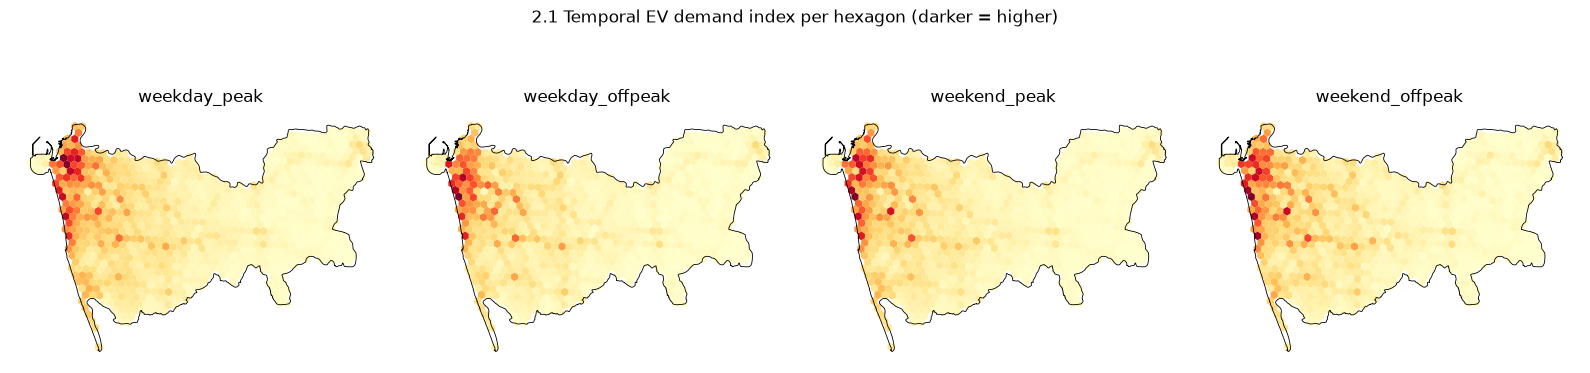

Rank correlation between periods (1 = same pattern):


,D_weekday_peak,D_weekday_offpeak,D_weekend_peak,D_weekend_offpeak
D_weekday_peak,1.00,0.98,1.00,0.99
D_weekday_offpeak,0.98,1.00,0.98,0.99
D_weekend_peak,1.00,0.98,1.00,0.99
D_weekend_offpeak,0.99,0.99,0.99,1.00


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
hx = hexes.set_index("h3").join(H[[f"D_{p}" for p in PERIODS]])
for ax, per in zip(axes, PERIODS):
    hx.plot(column=f"D_{per}", ax=ax, cmap="YlOrRd", legend=False, linewidth=0)
    district.boundary.plot(ax=ax, color="k", lw=0.6); ax.set_title(per); ax.set_axis_off()
fig.suptitle("2.1 Temporal EV demand index per hexagon (darker = higher)"); fig.tight_layout()
fig.savefig(FIG / "2_1_demand_by_period.png", dpi=120); plt.show()
corr = H[[f"D_{p}" for p in PERIODS]].corr(method="spearman").round(2)
print("Rank correlation between periods (1 = same pattern):"); display(corr)

## 2.2 Hotspots – K-Means vs DBSCAN

Clustering on hexagon centres weighted by temporal demand. **K-Means**: k chosen by elbow + silhouette.
**DBSCAN**: on the top-25 % demand hexagons, `eps` from the k-distance curve. The better method by
Silhouette (higher) / Davies-Bouldin (lower) is kept. Hotspot centres are **not** buildable sites – they guide
the search; real sites come from step 2.4.

K-Means k=3: {'silhouette': 0.41449224574863075, 'davies_bouldin': 0.8643298417263159} | DBSCAN eps=1.93 km: {'clusters': 1, 'noise_%': 5.0691244239631335, 'silhouette': None, 'davies_bouldin': None} -> keep kmeans


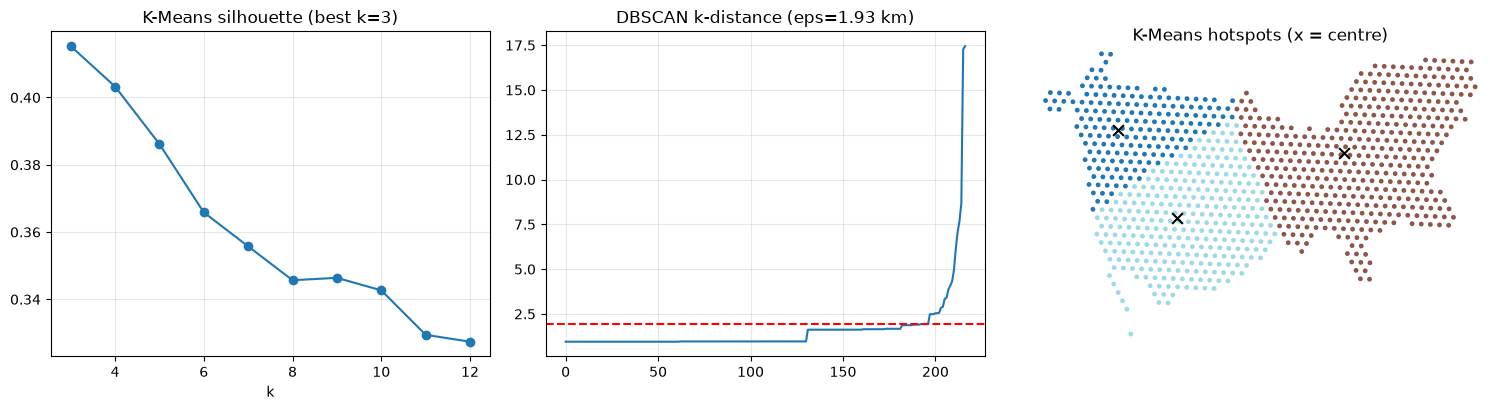

,silhouette,davies_bouldin
K-Means,0.414492,0.86433
DBSCAN,None,None


In [7]:
XY = H[["x", "y"]].to_numpy() / 1000  # km
wgt = H["D_temporal"].to_numpy()
ks = range(3, 13); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(XY, sample_weight=wgt)
    inertia.append(km.inertia_); sil.append(silhouette_score(XY, km.labels_))
K_BEST = list(ks)[int(np.argmax(sil))]
km = KMeans(n_clusters=K_BEST, n_init=20, random_state=SEED).fit(XY, sample_weight=wgt)
km_scores = {"silhouette": float(silhouette_score(XY, km.labels_)), "davies_bouldin": float(davies_bouldin_score(XY, km.labels_))}

top = H["D_temporal"] >= H["D_temporal"].quantile(0.75)
Xt = XY[top.values]
kd = np.sort(NearestNeighbors(n_neighbors=5).fit(Xt).kneighbors(Xt)[0][:, -1])
# knee of the k-distance curve = point farthest from the straight line between first and last value
xk = np.linspace(0, 1, len(kd)); yk = (kd - kd.min()) / (kd.max() - kd.min())
EPS = float(kd[np.argmax(xk - yk)])
db = DBSCAN(eps=EPS, min_samples=5).fit(Xt)
lab = db.labels_; ok = lab >= 0
db_scores = {"clusters": int(lab.max() + 1), "noise_%": float(100 * (~ok).mean()),
             "silhouette": float(silhouette_score(Xt[ok], lab[ok])) if lab.max() > 0 else None,
             "davies_bouldin": float(davies_bouldin_score(Xt[ok], lab[ok])) if lab.max() > 0 else None}
best = "kmeans" if (db_scores["silhouette"] is None or km_scores["silhouette"] >= db_scores["silhouette"]) else "dbscan"
print(f"K-Means k={K_BEST}: {km_scores} | DBSCAN eps={EPS:.2f} km: {db_scores} -> keep {best}")
RESULTS["metrics"]["2.2_hotspots"] = {"kmeans_k": K_BEST, "kmeans": km_scores, "dbscan_eps_km": EPS, "dbscan": db_scores, "kept": best}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(list(ks), sil, "o-"); ax[0].set_title(f"K-Means silhouette (best k={K_BEST})"); ax[0].set_xlabel("k")
ax[1].plot(kd); ax[1].axhline(EPS, color="r", ls="--"); ax[1].set_title(f"DBSCAN k-distance (eps={EPS:.2f} km)")
hexes.plot(ax=ax[2], color="0.92", linewidth=0)
ax[2].scatter(H.x, H.y, c=km.labels_, s=6, cmap="tab20"); ax[2].scatter(*(km.cluster_centers_ * 1000).T, c="k", marker="x", s=60)
ax[2].set_title("K-Means hotspots (x = centre)"); ax[2].set_axis_off()
for a in ax[2:]:
    a.set_xlim(H.x.min() - 500, H.x.max() + 500); a.set_ylim(H.y.min() - 500, H.y.max() + 500)
fig.tight_layout(); fig.savefig(FIG / "2_2_hotspots.png", dpi=120); plt.show()
pd.DataFrame({"K-Means": km_scores, "DBSCAN": {k: db_scores[k] for k in ("silhouette", "davies_bouldin")}}).T.round(3)

## 2.3 AHP criteria weights

Five criteria: **demand**, **grid** (spare capacity of nearest grid substation, closeness), **road access**,
**land** (site size, commercial land), **competition** (distance to existing chargers – farther is better).
Saaty 1–9 scale. ⚠️ The judgements below are a **placeholder** until the expert interviews (CLAUDE.md).
Consistency ratio (CR) must be < 0.10.

In [8]:
CRIT = ["demand", "grid", "road", "land", "competition"]
# ⚠️ ASSUMPTION – pairwise judgements (row criterion vs column criterion)
J = {("demand", "grid"): 2, ("demand", "road"): 3, ("demand", "land"): 4, ("demand", "competition"): 3,
     ("grid", "road"): 2, ("grid", "land"): 3, ("grid", "competition"): 2,
     ("road", "land"): 2, ("road", "competition"): 1, ("land", "competition"): 1 / 2}
A = np.ones((5, 5))
for (a, b), v in J.items():
    i, j = CRIT.index(a), CRIT.index(b); A[i, j], A[j, i] = v, 1 / v
eigval, eigvec = np.linalg.eig(A)
k = np.argmax(eigval.real); lam = eigval.real[k]
W = np.abs(eigvec[:, k].real); W = W / W.sum()
CI = (lam - 5) / 4; CR = CI / 1.12  # RI(5) = 1.12
AHP_W = pd.Series(W, index=CRIT)
RESULTS["metrics"]["2.3_ahp"] = {"weights": AHP_W.round(4).to_dict(), "lambda_max": float(lam), "CR": float(CR), "CR_ok": bool(CR < 0.1)}
display(pd.DataFrame(A, index=CRIT, columns=CRIT).round(2))
print("weights:", AHP_W.round(3).to_dict(), f"| CR = {CR:.3f} ->", "OK (< 0.10)" if CR < 0.1 else "NOT consistent")

,demand,grid,road,land,competition
demand,1.00,2.00,3.0,4.0,3.0
grid,0.50,1.00,2.0,3.0,2.0
road,0.33,0.50,1.0,2.0,1.0
land,0.25,0.33,0.5,1.0,0.5
competition,0.33,0.50,1.0,2.0,1.0


weights: {'demand': 0.403, 'grid': 0.244, 'road': 0.137, 'land': 0.079, 'competition': 0.137} | CR = 0.007 -> OK (< 0.10)


## 2.4 Candidate sites and MCDM scoring

Candidates = real buildable OSM sites inside the district: fuel stations, supermarkets, malls, car parks,
hotels, rest areas. Criteria per site (all scaled 0–1, 1 = better):
* **demand**: temporal demand of the site's hexagon + its 6 neighbours (static version for the baseline)
* **grid**: spare 2025 MVA of the nearest grid substation (CEB plan) ÷ distance factor
* **road**: closeness to a motorway / trunk / primary road
* **land**: site area (car parks / malls with mapped area score higher) + commercial land in the hexagon
* **competition**: distance to the nearest existing charger (farther = less overlap)

In [9]:
CAND_CATS = ["fuel_station", "supermarket", "mall", "car_park", "hotel", "rest_area"]
cand = pois[pois.in_district & pois.category.isin(CAND_CATS)].copy().reset_index(drop=True)
cand["h3"] = [h3.latlng_to_cell(g.y, g.x, RES_H3) for g in cand.geometry]
cand = cand[cand.h3.isin(H.index)].reset_index(drop=True)
cm = cand.to_crs(M)
ring = lambda c, col: H[col].reindex(list(h3.grid_disk(c, 1))).fillna(0).sum()
cand["demand_temporal"] = [ring(c, "D_temporal") for c in cand.h3]
cand["demand_static"] = [ring(c, "D_static") for c in cand.h3]
for per in PERIODS:
    cand[f"demand_{per}"] = [ring(c, f"D_{per}") for c in cand.h3]

major = roads[roads.road_class.isin(["motorway", "trunk", "primary"])].to_crs(M)
cand["dist_major_road_m"] = cm.geometry.apply(lambda g: major.distance(g).min()) if len(cand) < 400 else \
    gpd.sjoin_nearest(cm[["geometry"]], major[["geometry"]], distance_col="d").groupby(level=0)["d"].min().values
g = gss[gss.geometry.notna() & gss.serves_study_area].to_crs(M).reset_index(drop=True)
nn = gpd.sjoin_nearest(cm[["geometry"]], g[["ceb_name", "spare_2025_mva", "capacity_2025_mva", "geometry"]], distance_col="d_gss")
nn = nn[~nn.index.duplicated()]
cand["gss"] = nn["ceb_name"].values; cand["gss_spare_mva"] = nn["spare_2025_mva"].values; cand["dist_gss_m"] = nn["d_gss"].values
ex = chargers[chargers.in_study_area].to_crs(M)
cand["dist_charger_m"] = gpd.sjoin_nearest(cm[["geometry"]], ex[["geometry"]], distance_col="d").groupby(level=0)["d"].min().values
cand["site_area_m2"] = cand["site_area_m2"].fillna(0)
cand["commercial_share"] = H["commercial_share"].reindex(cand.h3).values
traffic = H["traffic_proxy"].reindex(cand.h3).values
cand["traffic_proxy"] = traffic
print(f"candidates: {len(cand)}"); display(cand.category.value_counts())

candidates: 1129


category
car_park        395
supermarket     330
hotel           217
fuel_station    137
mall             47
rest_area         3
Name: count, dtype: int64

In [10]:
def mm(s):
    s = pd.Series(s, dtype=float); r = s.max() - s.min()
    return (s - s.min()) / r if r > 0 else s * 0

def criteria(c, demand_col="demand_temporal"):
    return pd.DataFrame({
        "demand": mm(c[demand_col]),
        "grid": mm(c["gss_spare_mva"].fillna(0) / (1 + c["dist_gss_m"] / 2000)),
        "road": 1 - mm(np.log1p(c["dist_major_road_m"])),
        "land": 0.6 * mm(np.log1p(c["site_area_m2"])) + 0.4 * mm(c["commercial_share"]),
        "competition": mm(np.minimum(c["dist_charger_m"], 5000)),
    })

def score(c, w, demand_col="demand_temporal"):
    return (criteria(c, demand_col) * pd.Series(w)[CRIT]).sum(axis=1)

cand["score_ahp_temporal"] = score(cand, AHP_W)                                       # proposed
cand["score_ahp_static"] = score(cand, AHP_W, "demand_static")                        # baseline: static MCDM
cand["score_equal"] = score(cand, pd.Series(0.2, index=CRIT))                          # baseline: equal weights
cand["rank"] = cand["score_ahp_temporal"].rank(ascending=False, method="first").astype(int)
cols = ["rank", "category", "name", "gss", "score_ahp_temporal", "demand_temporal", "dist_major_road_m", "dist_gss_m", "gss_spare_mva", "dist_charger_m"]
display(cand.sort_values("rank")[cols].head(15).round(2))

,rank,category,name,gss,score_ahp_temporal,demand_temporal,dist_major_road_m,dist_gss_m,gss_spare_mva,dist_charger_m
1093,1,car_park,NaN,Sub P (Town Hall),0.74,2.12,22.93,137.44,57.0,904.50
1095,2,car_park,NaN,Sub P (Town Hall),0.74,2.12,29.66,92.97,57.0,888.84
952,3,car_park,NaN,Sub P (Town Hall),0.73,2.12,27.52,170.07,57.0,689.10
1086,4,car_park,NaN,Sub P (Town Hall),0.73,2.30,8.76,720.08,57.0,559.16
1096,5,car_park,NaN,Sub P (Town Hall),0.73,2.12,60.86,128.58,57.0,791.68
820,6,car_park,NaN,Sub P (Town Hall),0.72,2.12,80.96,137.73,57.0,798.75
501,7,mall,NaN,Sub P (Town Hall),0.72,2.12,25.31,41.77,57.0,817.32
1085,8,car_park,NaN,Sub P (Town Hall),0.72,2.30,8.62,797.76,57.0,423.08
1084,9,car_park,NaN,Sub P (Town Hall),0.72,2.30,8.25,763.52,57.0,480.35
735,10,car_park,NaN,Sub P (Town Hall),0.71,2.12,57.51,379.95,57.0,885.91


## 2.5 MCLP with substation capacity constraint

Choose **N** sites that maximise demand covered within **3 km** (urban service distance, CLAUDE.md):

max Σ D_h·y_h + ε Σ score_j·x_j  s.t.  y_h ≤ Σ_{j covers h} x_j ,  Σ x_j ≤ N (= N without grid limit) ,  **Σ_{j at substation s} P·x_j ≤ C_s** , binary.

`C_s` = EV allowance of grid substation s = spare 2025 MVA × power factor 0.9 × **share for EV** ⚠️.
`P` = power of one new station (growth scenario) ⚠️. All buildable candidates are allowed; the MCDM score breaks ties between sites that cover the same demand.
Solver: SciPy `milp` (HiGHS).

In [11]:
N_SITES, RADIUS_M, PF, EV_SHARE, EPS_SCORE = 15, 3000, 0.9, 0.20, 1e-3
SCENARIOS = {"low": 0.25, "medium": 0.5, "high": 1.0}  # MW per new station
RESULTS["config"]["mclp"] = {"N_SITES": N_SITES, "RADIUS_M": RADIUS_M, "power_factor": PF, "EV_share_of_spare": EV_SHARE,
                             "station_MW_by_scenario": SCENARIOS, "H3_res": RES_H3}
pool = cand.sort_values("rank").reset_index(drop=True)   # all candidates
pm = pool.to_crs(M)
tree = cKDTree(H[["x", "y"]].to_numpy())
cover = tree.query_ball_point(np.c_[pm.geometry.x, pm.geometry.y], r=RADIUS_M)   # hexes covered by each site
gss_ids = {n: i for i, n in enumerate(sorted(pool.gss.unique()))}
allow = g.set_index("ceb_name")["spare_2025_mva"].clip(lower=0) * PF * EV_SHARE      # MW for EV per substation

def solve_mclp(D, station_mw=None, n=N_SITES, score=None):
    nJ, nH = len(pool), len(D)
    c = np.r_[-(EPS_SCORE * (score if score is not None else pool.score_ahp_temporal.to_numpy())), -D]
    r, cc, v = [], [], []
    for j, hs in enumerate(cover):
        for h in hs: r.append(h); cc.append(j); v.append(-1.0)
    r += list(range(nH)); cc += [nJ + h for h in range(nH)]; v += [1.0] * nH
    cons = [LinearConstraint(sparse.csr_matrix((v, (r, cc)), shape=(nH, nJ + nH)), -np.inf, 0),
            LinearConstraint(np.r_[np.ones(nJ), np.zeros(nH)][None, :], 0 if station_mw is not None else n, n)]  # grid may allow fewer
    if station_mw is not None:
        rows = np.zeros((len(gss_ids), nJ + nH))
        for j, s in enumerate(pool.gss): rows[gss_ids[s], j] = station_mw
        cap = np.array([allow.get(s, 0) for s in sorted(gss_ids)])
        cons.append(LinearConstraint(rows, -np.inf, cap))
    t = time.time()
    res = milp(c, constraints=cons, integrality=np.r_[np.ones(nJ), np.zeros(nH)], bounds=Bounds(0, 1),
               options={"time_limit": 120})
    if res.x is None:
        return np.array([], dtype=int), time.time() - t, res.status
    return np.flatnonzero(res.x[:nJ] > 0.5), time.time() - t, res.status

def evaluate(sel_xy, station_mw, gss_of_sel=None):
    covered = np.zeros(len(H), bool)
    for hs in tree.query_ball_point(sel_xy, r=RADIUS_M): covered[hs] = True
    out = {f"coverage_{p}_%": 100 * H[f"D_{p}"].to_numpy()[covered].sum() / H[f"D_{p}"].sum() for p in PERIODS}
    out["coverage_temporal_%"] = 100 * H.D_temporal.to_numpy()[covered].sum() / H.D_temporal.sum()
    if gss_of_sel is not None:
        load = pd.Series(gss_of_sel).value_counts() * station_mw
        out["grid_violations"] = int((load > load.index.map(lambda s: allow.get(s, 0)) + 1e-9).sum())
        out["grid_overload_MW"] = float((load - load.index.map(lambda s: allow.get(s, 0))).clip(lower=0).sum())
    return out

In [12]:
D = H["D_temporal"].to_numpy()
xy_pool = np.c_[pm.geometry.x, pm.geometry.y]
rows, selections = [], {}
for scen, mw in SCENARIOS.items():
    sel, t_s, st = solve_mclp(D, mw); selections[("MCLP + grid (proposed)", scen)] = sel
    rows.append({"method": "MCLP + grid (proposed)", "scenario": scen, "runtime_s": t_s, "status": st, "sites": len(sel),
                 **evaluate(xy_pool[sel], mw, pool.gss.values[sel])})
    sel0, t0, st0 = solve_mclp(D, None); selections[("MCLP without grid", scen)] = sel0
    rows.append({"method": "MCLP without grid", "scenario": scen, "runtime_s": t0, "status": st0, "sites": len(sel0),
                 **evaluate(xy_pool[sel0], mw, pool.gss.values[sel0])})
    # baseline: traffic-only top-N (from all candidates)
    tsel = cand.nlargest(N_SITES, "traffic_proxy"); tm = tsel.to_crs(M)
    rows.append({"method": "Traffic-only top-N", "scenario": scen, **evaluate(np.c_[tm.geometry.x, tm.geometry.y], mw, tsel.gss.values)})
    # baseline: static MCDM top-N
    ssel = cand.nlargest(N_SITES, "score_ahp_static"); sm_ = ssel.to_crs(M)
    rows.append({"method": "Static MCDM top-N", "scenario": scen, **evaluate(np.c_[sm_.geometry.x, sm_.geometry.y], mw, ssel.gss.values)})
    # baseline: K-Means centres only (k = N, demand-weighted; centres are not real sites)
    kmN = KMeans(n_clusters=N_SITES, n_init=20, random_state=SEED).fit(H[["x", "y"]].to_numpy(), sample_weight=D)
    cg = gpd.GeoDataFrame(geometry=gpd.points_from_xy(*kmN.cluster_centers_.T), crs=M)
    cgs = gpd.sjoin_nearest(cg, g[["ceb_name", "geometry"]]).ceb_name.values[:N_SITES]
    rows.append({"method": "K-Means centres only", "scenario": scen, **evaluate(kmN.cluster_centers_, mw, cgs)})
CMP = pd.DataFrame(rows)
RESULTS["metrics"]["2.5_mclp_comparison"] = CMP.round(3).to_dict(orient="records")
show = ["method", "scenario", "sites", "coverage_temporal_%", *[f"coverage_{p}_%" for p in PERIODS], "grid_violations", "grid_overload_MW"]
display(CMP[show].round(1))

,method,scenario,sites,coverage_temporal_%,coverage_weekday_peak_%,coverage_weekday_offpeak_%,coverage_weekend_peak_%,coverage_weekend_offpeak_%,grid_violations,grid_overload_MW
0,MCLP + grid (proposed),low,15.0,85.3,84.7,85.4,85.7,85.3,0,0.0
1,MCLP without grid,low,15.0,85.3,84.7,85.4,85.7,85.3,0,0.0
2,Traffic-only top-N,low,NaN,14.8,14.2,15.0,14.6,14.7,1,0.7
3,Static MCDM top-N,low,NaN,18.4,18.3,18.5,18.9,18.2,0,0.0
4,K-Means centres only,low,NaN,77.9,76.8,78.2,77.6,77.6,0,0.0
5,MCLP + grid (proposed),medium,15.0,84.3,83.8,84.4,84.8,84.3,0,0.0
6,MCLP without grid,medium,15.0,85.3,84.7,85.4,85.7,85.3,1,0.1
7,Traffic-only top-N,medium,NaN,14.8,14.2,15.0,14.6,14.7,1,4.2
8,Static MCDM top-N,medium,NaN,18.4,18.3,18.5,18.9,18.2,0,0.0
9,K-Means centres only,medium,NaN,77.9,76.8,78.2,77.6,77.6,1,0.1


coverage_temporal_%              grid_violations       \
scenario                              high   low medium            high  low   
method                                                                         
K-Means centres only                  77.9  77.9   77.9             2.0  0.0   
MCLP + grid (proposed)                84.2  85.3   84.3             0.0  0.0   
MCLP without grid                     85.3  85.3   85.3             2.0  0.0   
Static MCDM top-N                     18.4  18.4   18.4             0.0  0.0   
Traffic-only top-N                    14.8  14.8   14.8             1.0  1.0   

                               
scenario               medium  
method                         
K-Means centres only      1.0  
MCLP + grid (proposed)    0.0  
MCLP without grid         1.0  
Static MCDM top-N         0.0  
Traffic-only top-N        1.0

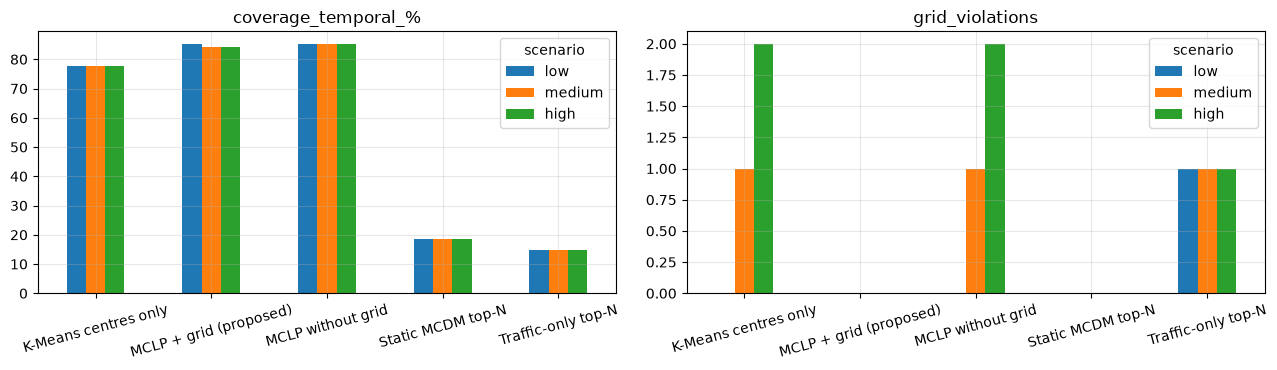

In [13]:
piv = CMP.pivot_table(index="method", columns="scenario", values=["coverage_temporal_%", "grid_violations"]).round(1)
display(piv)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, col in zip(ax, ["coverage_temporal_%", "grid_violations"]):
    CMP.pivot(index="method", columns="scenario", values=col)[list(SCENARIOS)].plot.bar(ax=a, rot=15)
    a.set_title(col); a.set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "2_5_method_comparison.png", dpi=120); plt.show()

### When does the grid limit matter? (stress test)
With small stations no substation reaches its EV allowance, so MCLP with and without the grid constraint pick the
same sites. Here the station size is increased step by step (e.g. bigger DC hubs as EV numbers grow): the
**unconstrained** MCLP starts overloading substations, while the **grid-aware** MCLP keeps 0 violations and gives up
only a little coverage.

,station_MW,sites_with_grid,coverage_grid_%,violations_grid,coverage_no_grid_%,violations_no_grid,overload_no_grid_MW
0,0.5,15,84.28,0,85.31,1,0.10
1,1.0,15,84.16,0,85.31,2,1.13
2,2.0,15,81.63,0,85.31,2,4.13
3,3.0,15,78.93,0,85.31,3,8.05
4,4.0,15,75.65,0,85.31,5,15.25
5,6.0,10,53.83,0,85.31,8,35.60


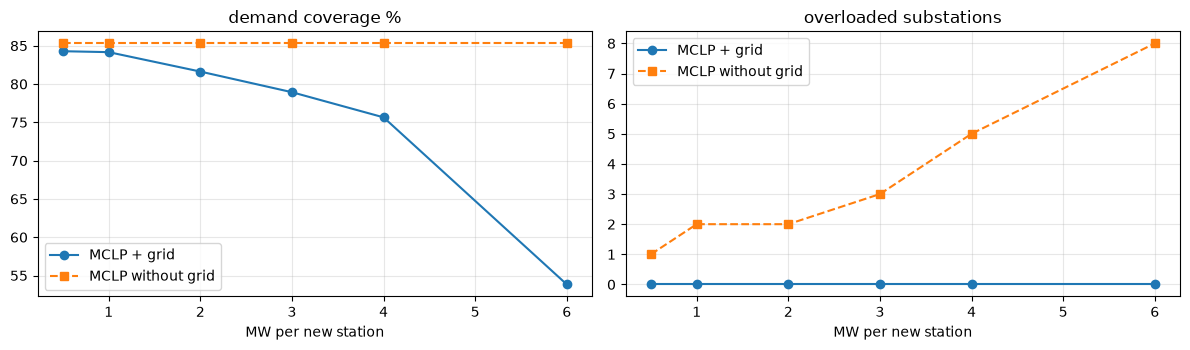

In [14]:
stress = []
for mw in (0.5, 1, 2, 3, 4, 6):
    s1, _, st1 = solve_mclp(D, mw); s0, _, _ = solve_mclp(D, None)
    e1 = evaluate(xy_pool[s1], mw, pool.gss.values[s1]) if len(s1) else {"coverage_temporal_%": 0.0, "grid_violations": 0, "grid_overload_MW": 0.0}
    e0 = evaluate(xy_pool[s0], mw, pool.gss.values[s0])
    stress.append({"station_MW": mw, "sites_with_grid": len(s1),
                   "coverage_grid_%": e1["coverage_temporal_%"], "violations_grid": e1["grid_violations"],
                   "coverage_no_grid_%": e0["coverage_temporal_%"], "violations_no_grid": e0["grid_violations"],
                   "overload_no_grid_MW": e0["grid_overload_MW"]})
STRESS = pd.DataFrame(stress)
RESULTS["metrics"]["2.5_grid_stress_test"] = STRESS.round(3).to_dict(orient="records")
display(STRESS.round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(STRESS.station_MW, STRESS["coverage_grid_%"], "o-", label="MCLP + grid")
ax[0].plot(STRESS.station_MW, STRESS["coverage_no_grid_%"], "s--", label="MCLP without grid"); ax[0].set_title("demand coverage %")
ax[1].plot(STRESS.station_MW, STRESS["violations_grid"], "o-", label="MCLP + grid")
ax[1].plot(STRESS.station_MW, STRESS["violations_no_grid"], "s--", label="MCLP without grid"); ax[1].set_title("overloaded substations")
for a in ax: a.set_xlabel("MW per new station"); a.legend()
fig.tight_layout(); fig.savefig(FIG / "2_5_grid_stress_test.png", dpi=120); plt.show()

## Validation

1. **Hold-out of existing stations:** remove the "distance to existing charger" criterion, re-run, and check how many
   real chargers (OSM, district) have a selected site within 1.5 km – does the method find places where operators
   already built? (OSM list is incomplete → indicative only.)
2. **Weight sensitivity (±20 %)**: change each AHP weight by −20 % / +20 % (re-normalise), re-rank: top-10 overlap
   (target ≥ 70 %) and Kendall τ of the full ranking.

In [15]:
w_hold = AHP_W.copy(); w_hold["competition"] = 0; w_hold /= w_hold.sum()
hold_score = score(pool, w_hold).to_numpy()
sel_h, _, _ = solve_mclp(D, SCENARIOS["medium"], score=hold_score)
ex_d = chargers[chargers.in_district].to_crs(M)
d_ex = cKDTree(xy_pool[sel_h]).query(np.c_[ex_d.geometry.x, ex_d.geometry.y])[0]
tr_top = cand.nlargest(N_SITES, "traffic_proxy").to_crs(M)
d_tr = cKDTree(np.c_[tr_top.geometry.x, tr_top.geometry.y]).query(np.c_[ex_d.geometry.x, ex_d.geometry.y])[0]
hold = {"existing_chargers": len(ex_d), "hit_rate_1.5km_proposed_%": 100 * float(np.mean(d_ex <= 1500)),
        "hit_rate_1.5km_traffic_only_%": 100 * float(np.mean(d_tr <= 1500))}
RESULTS["metrics"]["validation_holdout"] = hold; print(hold)

base_rank = cand["score_ahp_temporal"]; top10 = set(base_rank.nlargest(10).index)
sens = []
for c_ in CRIT:
    for f in (0.8, 1.2):
        w = AHP_W.copy(); w[c_] *= f; w /= w.sum()
        s = score(cand, w)
        sens.append({"criterion": c_, "change": f"{round((f - 1) * 100):+d}%",
                     "top10_overlap_%": 10 * len(top10 & set(s.nlargest(10).index)),
                     "kendall_tau": float(kendalltau(base_rank, s)[0])})
SENS = pd.DataFrame(sens)
RESULTS["metrics"]["validation_sensitivity"] = {"min_top10_overlap_%": float(SENS["top10_overlap_%"].min()),
    "mean_top10_overlap_%": float(SENS["top10_overlap_%"].mean()), "min_kendall_tau": float(SENS.kendall_tau.min()),
    "target_met": bool(SENS["top10_overlap_%"].min() >= 70), "table": SENS.round(3).to_dict(orient="records")}
display(SENS.round(3))

{'existing_chargers': 22, 'hit_rate_1.5km_proposed_%': 50.0, 'hit_rate_1.5km_traffic_only_%': 13.636363636363635}


,criterion,change,top10_overlap_%,kendall_tau
0,demand,-20%,100,0.961
1,demand,+20%,90,0.970
2,grid,-20%,90,0.972
3,grid,+20%,90,0.974
4,road,-20%,100,0.979
5,road,+20%,90,0.980
6,land,-20%,90,0.985
7,land,+20%,100,0.986
8,competition,-20%,100,0.965
9,competition,+20%,100,0.964


## Selected sites (medium growth scenario) – map and export

,name,category,operator,gss,gss_spare_mva,dist_gss_m,dist_major_road_m,dist_charger_m,score_ahp_temporal,demand_temporal,lat,lon
1,NaN,car_park,NaN,Sub P (Town Hall),57.0,170.07,27.52,689.10,0.73,2.12,6.92,79.87
2,Lanka Filling Station,fuel_station,Ceypetco,Kelanitissa,56.5,353.34,14.06,548.03,0.50,1.08,6.96,79.88
3,Cargills Food City,supermarket,Cargills Food City,Sub A (Havelock Town),36.4,2112.96,8.05,2019.11,0.45,1.26,6.88,79.88
4,NaN,car_park,Glomark,Sri Jayawardanapura,22.3,1244.55,26.32,2809.38,0.43,1.02,6.88,79.93
5,Cargills Food City,supermarket,Cargills Food City,Kesbewa,28.2,159.26,19.00,5364.13,0.43,0.58,6.80,79.94
6,NaN,car_park,NaN,Athurugiriya,32.8,1802.20,134.92,5732.03,0.39,0.61,6.91,79.97
7,Keells,supermarket,NaN,Kesbewa,28.2,4108.86,37.52,5940.89,0.32,0.47,6.79,79.98
8,NKsea Food,hotel,NaN,Ratmalana,40.4,2401.47,17.19,1562.26,0.32,0.63,6.83,79.89
9,Sathosa,supermarket,NaN,Pannipitiya,8.2,2135.54,11.81,2104.43,0.31,0.86,6.84,79.92
10,NaN,car_park,NaN,Battaramulla,31.8,2335.95,84.50,321.30,0.28,0.74,6.92,79.92


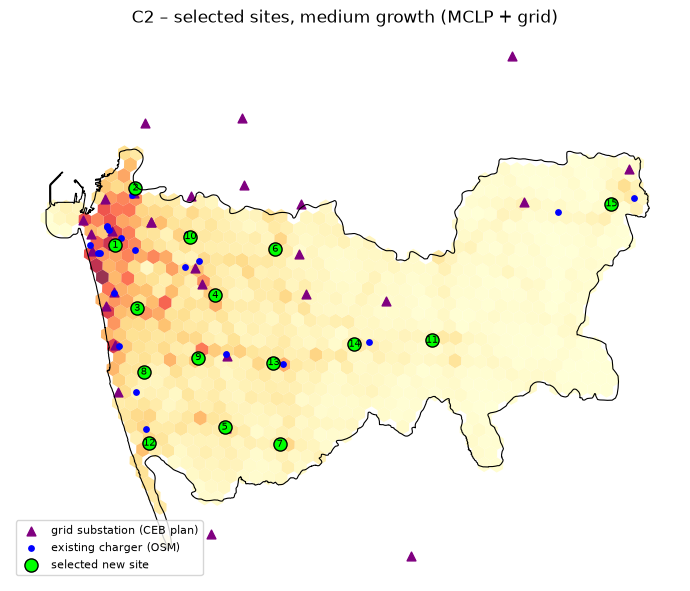

In [16]:
sel = selections[("MCLP + grid (proposed)", "medium")]
SITES = pool.iloc[sel][["name", "category", "operator", "gss", "gss_spare_mva", "dist_gss_m", "dist_major_road_m",
                        "dist_charger_m", "score_ahp_temporal", "demand_temporal", "geometry"]].copy()
SITES["lat"], SITES["lon"] = SITES.geometry.y, SITES.geometry.x
SITES = SITES.sort_values("score_ahp_temporal", ascending=False).reset_index(drop=True)
SITES.index += 1
SITES.to_file(RES / f"c2_selected_sites_{RUN_ID}.geojson", driver="GeoJSON")
SITES.drop(columns="geometry").to_csv(RES / f"c2_selected_sites_{RUN_ID}.csv")
display(SITES.drop(columns="geometry").round(2))

fig, ax = plt.subplots(figsize=(7, 8))
hexes.set_index("h3").join(H[["D_temporal"]]).plot(column="D_temporal", cmap="YlOrRd", ax=ax, linewidth=0, alpha=0.8)
district.boundary.plot(ax=ax, color="k", lw=0.8)
g.to_crs(4326).plot(ax=ax, marker="^", color="purple", markersize=40, label="grid substation (CEB plan)")
chargers[chargers.in_district].plot(ax=ax, color="blue", markersize=15, label="existing charger (OSM)")
SITES.plot(ax=ax, color="lime", edgecolor="k", markersize=90, label="selected new site")
for i, r in SITES.iterrows(): ax.annotate(str(i), (r.lon, r.lat), fontsize=7, ha="center", va="center")
ax.legend(loc="lower left", fontsize=8); ax.set_title("C2 – selected sites, medium growth (MCLP + grid)"); ax.set_axis_off()
fig.tight_layout(); fig.savefig(FIG / "2_5_selected_sites_map.png", dpi=130); plt.show()

In [17]:
import folium
mp = folium.Map(location=[DIST.centroid.y, DIST.centroid.x], zoom_start=11, tiles="OpenStreetMap")
folium.Choropleth(geo_data=hexes.set_index("h3").join(H[["D_temporal"]]).reset_index().to_json(), data=H.reset_index(),
                  columns=["h3", "D_temporal"], key_on="feature.properties.h3", fill_color="YlOrRd", line_opacity=0,
                  fill_opacity=0.5, legend_name="temporal demand index").add_to(mp)
for _, r in g.to_crs(4326).iterrows():
    folium.RegularPolygonMarker([r.geometry.y, r.geometry.x], number_of_sides=3, radius=7, color="purple", fill=True,
        popup=f"{r.ceb_name}<br>capacity 2025: {r.capacity_2025_mva} MVA<br>spare: {r.spare_2025_mva} MVA (CEB 2013 plan)").add_to(mp)
for i, r in SITES.iterrows():
    folium.Marker([r.lat, r.lon], icon=folium.Icon(color="green", icon="flash"),
        popup=f"#{i} {r['name'] or r.category}<br>{r.category}<br>score {r.score_ahp_temporal:.2f}<br>GSS: {r.gss}").add_to(mp)
mp.save(RES / f"c2_sites_map_{RUN_ID}.html"); print("interactive map saved:", f"results/c2_sites_map_{RUN_ID}.html")

interactive map saved: results/c2_sites_map_20261019T092728Z.html


## ✅ C2 results summary

The proposed method (temporal demand + real candidates + AHP-MCDM + **grid-constrained MCLP**) vs the baselines,
**medium growth scenario**. Coverage = share of EV demand within 3 km of a selected site (higher = better);
grid violations = substations whose EV allowance is exceeded (must be 0).

In [18]:
med = CMP[CMP.scenario == "medium"].set_index("method")
SUMMARY = med[["coverage_temporal_%", "coverage_weekday_peak_%", "coverage_weekend_peak_%", "grid_violations", "grid_overload_MW"]].copy()
SUMMARY.loc[:, "proposed"] = SUMMARY.index == "MCLP + grid (proposed)"
def hl(r): return ["font-weight: bold; background-color: #e8f5e9" if r.name == "MCLP + grid (proposed)" else "" for _ in r]
display(SUMMARY.style.apply(hl, axis=1).format("{:.1f}", subset=["coverage_temporal_%", "coverage_weekday_peak_%", "coverage_weekend_peak_%", "grid_overload_MW"]))
other = {
    "AHP consistency ratio (target < 0.10)": RESULTS["metrics"]["2.3_ahp"]["CR"],
    "Hotspots kept": f"{best} (K-Means sil {km_scores['silhouette']:.2f} / DBSCAN sil {db_scores['silhouette']})",
    "Top-10 overlap under ±20 % weights (min, target ≥ 70 %)": RESULTS["metrics"]["validation_sensitivity"]["min_top10_overlap_%"],
    "Kendall τ under ±20 % weights (min)": round(RESULTS["metrics"]["validation_sensitivity"]["min_kendall_tau"], 3),
    "Hold-out hit rate ≤ 1.5 km: proposed vs traffic-only (%)": f"{hold['hit_rate_1.5km_proposed_%']:.0f} vs {hold['hit_rate_1.5km_traffic_only_%']:.0f}",
    "MCLP runtime (s, medium)": round(float(med.loc['MCLP + grid (proposed)', 'runtime_s']), 2),
    "Grid stress: first station size where MCLP-without-grid overloads a substation (MW)": next((float(r.station_MW) for r in STRESS.itertuples() if r.violations_no_grid > 0), "none up to 6 MW"),
}
display(pd.Series(other, name="value").to_frame())

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
RESULTS["summary_medium"] = SUMMARY.reset_index().to_dict(orient="records")
(RES / f"c2_training_{RUN_ID}.json").write_text(json.dumps(clean(RESULTS), indent=2))
print("saved results/c2_training_%s.json" % RUN_ID)

,coverage_temporal_%,coverage_weekday_peak_%,coverage_weekend_peak_%,grid_violations,grid_overload_MW,proposed
method,,,,,,
MCLP + grid (proposed),84.3,83.8,84.8,0,0.0,True
MCLP without grid,85.3,84.7,85.7,1,0.1,False
Traffic-only top-N,14.8,14.2,14.6,1,4.2,False
Static MCDM top-N,18.4,18.3,18.9,0,0.0,False
K-Means centres only,77.9,76.8,77.6,1,0.1,False


,value
AHP consistency ratio (target < 0.10),0.007392
Hotspots kept,kmeans (K-Means sil 0.41 / DBSCAN sil None)
"Top-10 overlap under ±20 % weights (min, target ≥ 70 %)",90.0
Kendall τ under ±20 % weights (min),0.961
Hold-out hit rate ≤ 1.5 km: proposed vs traffic-only (%),50 vs 14
"MCLP runtime (s, medium)",12.54
Grid stress: first station size where MCLP-without-grid overloads a substation (MW),0.5


saved results/c2_training_20261019T092728Z.json


## Notes for the thesis / next steps
* ⚠️ **Assumptions to replace:** AHP judgements (expert interviews), POI period weights (Sri Lankan survey / pilot),
  EV share of substation spare capacity and station size (supervisor / CEB), substation capacity (CEB 2013 plan → current data).
* Existing chargers from OSM are incomplete → hold-out hit rate is indicative; repeat with operator lists.
* Expressway corridor (25 km service distance) not included yet – add when the supervisor chooses it.
* No integration with C1 yet (team decision): growth scenarios here use fixed station sizes; later C1 forecasts set them.